# MSTID modelling with Hooke's (1968) TID model over IRI/MSIS backgrounds

Pipeline: **IRI** background $N_e$ → **MSIS** neutral atmosphere → dissipative gravity-wave structure (Hines 1960; Vadas & Fritts 2005) → ion drift in the **IGRF** field → linearised continuity equation (Hooke 1968).

All parameters live in `config.py`; edit them there and re-run the notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm, TwoSlopeNorm
from datetime import datetime, timedelta, timezone

from config import *
from iri_msis_gw import iri_profiles, gw_struct, msis_profiles
from numerical_model import hooke_delta, I_deg, D_deg, B0

print(f"Site {lat0:.2f}N {lon0:.2f}E, {t0:%Y-%m-%d}; F10.7={F107}, Ap={AP}")
print(f"Wave: T={period} min, lambda_h={lambda_h} km, azimuth={azimuth} deg, c={c_phase:.1f} m/s")
print(f"IGRF at 300 km: I={I_deg:.1f} deg, D={D_deg:.1f} deg, B={B0*1e9:.0f} nT")

Site 69.12N 20.00E, 2020-12-08; F10.7=82.4, Ap=4
Wave: T=40 min, lambda_h=200 km, azimuth=170 deg, c=83.3 m/s
IGRF at 300 km: I=78.0 deg, D=8.5 deg, B=47332 nT


## 1. Background ionosphere (IRI)

In [2]:
# background profiles and altitude-time map
def latlon_grid(x_km, y_km):
    lat = lat0 + np.rad2deg(y_km * 1e3/RE)
    lon = lon0 + np.rad2deg(x_km * 1e3 /(RE * np.cos(np.deg2rad(lat))))
    return lat, lon

N0c_3d, F2c = iri_profiles(ut, lat0, lon0, altF)
N0c = N0c_3d[:, 0, :]
hmF2 = F2c["hm"][:, 0]; 
NmF2 = F2c["Nm"][:,0]; foF2 = F2c["fo"][:, 0]
doy = (t0 - datetime(yr, 1, 1, tzinfo=timezone.utc)).days + 1
decl = -23.44 * np.cos(np.deg2rad(360 /365 * (doy + 10)))

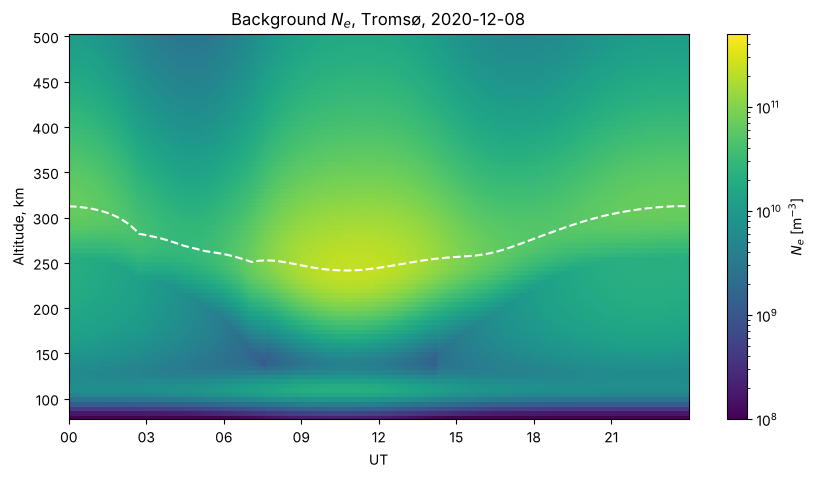

In [3]:
fig, axs = plt.subplots(figsize=(10, 5))
ax = axs

pcm = axs.pcolormesh(times, alt, N0c[:, ialtF_out].T, norm=LogNorm(1e8, 5e11), cmap="viridis",shading="nearest", edgecolors="face", linewidth=0.25)
ax.plot(times, hmF2, color="w", lw=1.5, ls="--", label="hmF2")
ax.set_ylabel("Altitude, km"); ax.set_xlabel("UT")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H"))
ax.set_title(f"Background $N_e$, Tromsø, {t0:%Y-%m-%d}")
fig.colorbar(pcm, ax=ax, label=r"$N_e$ [m$^{-3}$]")
plt.show()

## 2. Neutral atmosphere and gravity-wave vertical structure

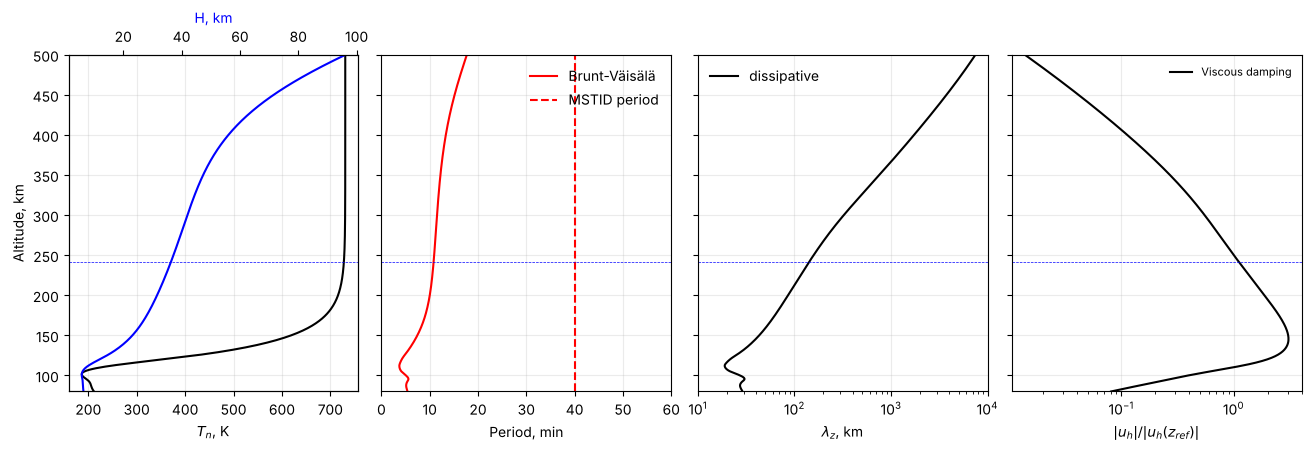

In [4]:
ms_c = msis_profiles(ut, altF)
gw_c = gw_struct(ms_c, altF)

it_max = np.argmax(NmF2)
iz_hm = np.argmin(np.abs(altF - hmF2[it_max]))
diss_z = altF[np.argmax(gw_c["diss_ratio"][it_max] > 1)] if np.any(gw_c["diss_ratio"][it_max] > 1) else np.nan
z_max = altF[np.argmax(gw_c["a"][it_max])]
t_lbl = f"{times[it_max]:%H:%M} UT"

g = {k: v[it_max] for k, v in gw_c.items() if isinstance(v, np.ndarray) and v.ndim == 2}
fig, axs = plt.subplots(1, 4, figsize=(13, 4.4), sharey= True, constrained_layout=True)
axs[0].plot(g["Tn"], altF,"k")
axs[0].set_ylabel("Altitude, km")
axs[0].set_xlabel("$T_n$, K")
ax0b = axs[0].twiny();ax0b.plot(g["H"] / 1e3, altF, color="b")
ax0b.set_xlabel("H, km", color="b")
#
axs[1].plot(g["T_BV"] /60, altF, "r", label ="Brunt-Väisälä")
axs[1].axvline(period, ls="--", color="r", label="MSTID period")
axs[1].set_xlabel("Period, min")
axs[1].set_xlim(0, 60)
axs[1].legend(frameon=False, fontsize=10)

#
#axs[2].plot(g["lamZ_inv"] / 1e3, altF, color="0.6", ls="--", label="Inviscid")
axs[2].plot(g["lamZ"] / 1e3, altF, color="k", label = "dissipative")
axs[2].set_xscale("log")
axs[2].set_xlim(10, 1e4)
axs[2].set_xlabel(r"$\lambda_z$, km")
axs[2].legend(frameon=False, fontsize=10)

#
#axs[3].semilogx(g["a_nodamp"], altF, color="k", ls = "--", label=r"No damping $\propto e^{z/2H}$")
axs[3].semilogx(g["a"], altF, color="k", label="Viscous damping")
#axs[3].axhline(diss_z, color="r", lw=0.8, ls=":", label=r"$\nu k^2/\omega = 1$")
axs[3].set_xlabel(r"$|u_h|/|u_h(z_{ref})|$")
axs[3].legend(frameon=False, fontsize=8)

for ax in axs:
    ax.axhline(hmF2[it_max], color="b",ls="--",lw = 0.5)
    ax.grid(alpha=0.25) 
axs[0].set_ylim(alt[0], alt[-1])
plt.show()

## 3. Hooke (1968) TID response: altitude–time

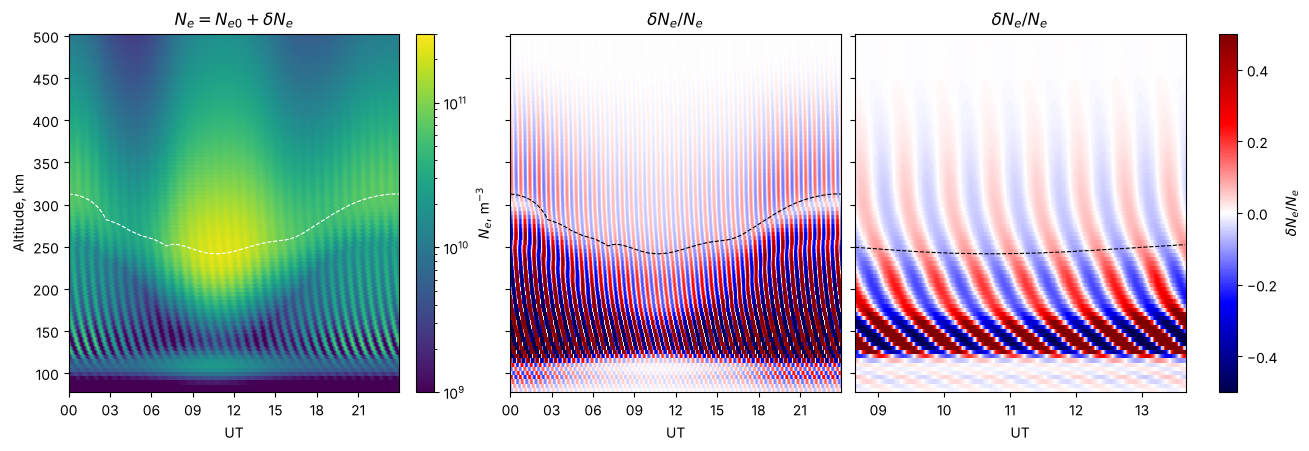

Wind amplitude at z_ref needed for 10% at hmF2: 12.5-56.5 m/s (horizontal wind at hmF2: 13.8-31.5 m/s)


In [5]:
# Hooke 1968 TID model
dH_unit, uh_unit = hooke_delta(N0c, gw_c, ms_c)
amp_hm = np.array([np.interp(hmF2[i], altF, np.abs(dH_unit[i])) for i in range(len(ut))])
U0 = amp_Fpeak /amp_hm  
dH_c = dH_unit * U0[:, None]
uh_hm = U0 * np.array([np.interp(hmF2[i], altF, np.abs(uh_unit[i])) for i in range(len(ut))])

tsec = ut * 3600
phase_t = np.exp(-1j *omega * tsec)[:, None]
Ne_H = N0c * np.exp(np.real(dH_c * phase_t))
delta_H = Ne_H / N0c - 1

fig, axs = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True, constrained_layout=True)

ax = axs[0]
pc_Ne = ax.pcolormesh(times, alt, Ne_H[:, ialtF_out].T, norm=LogNorm(1e9, 3e11), cmap="viridis",
                      shading="nearest", edgecolors="face", linewidth=0.25)
ax.plot(times, hmF2, color="w", lw=0.8, ls="--")
ax.set_ylabel("Altitude, km"); ax.set_title(r"$N_e = N_{e0} + \delta N_e$")
fig.colorbar(pc_Ne, ax=ax, label=r"$N_e$, m$^{-3}$")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H")); ax.set_xlabel("UT")

norm = TwoSlopeNorm(vcenter=0, vmin=-5*amp_Fpeak, vmax=5*amp_Fpeak)
ax = axs[1]
pc_amp = ax.pcolormesh(times, alt, delta_H[:, ialtF_out].T, norm=norm, cmap="seismic", shading="nearest")
ax.plot(times, hmF2, color="k", lw=0.8, ls="--")
ax.set_title(r"$\delta N_e / N_e$")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H")); 
ax.set_xlabel("UT")

win = (ut >= ut[it_max] - 2.5) & (ut <= ut[it_max] + 2.5)
ax = axs[2]
pc_sel = ax.pcolormesh(times[win], alt, delta_H[win][:, ialtF_out].T, norm=norm, cmap="seismic", shading="nearest")
ax.plot(times[win], hmF2[win], color="k", lw=0.8, ls="--")
ax.set_title(r"$\delta N_e / N_e$")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H"));
ax.set_xlabel("UT")

fig.colorbar(pc_sel, ax=axs[1:], label=r"$\delta N_e / N_e$")  
plt.show()

print(f"Wind amplitude at z_ref needed for {amp_Fpeak:.0%} at hmF2: "
      f"{U0.min():.1f}-{U0.max():.1f} m/s (horizontal wind at hmF2: {uh_hm.min():.1f}-{uh_hm.max():.1f} m/s)")

## 4. Vertical structure of the TID at the NmF2 maximum

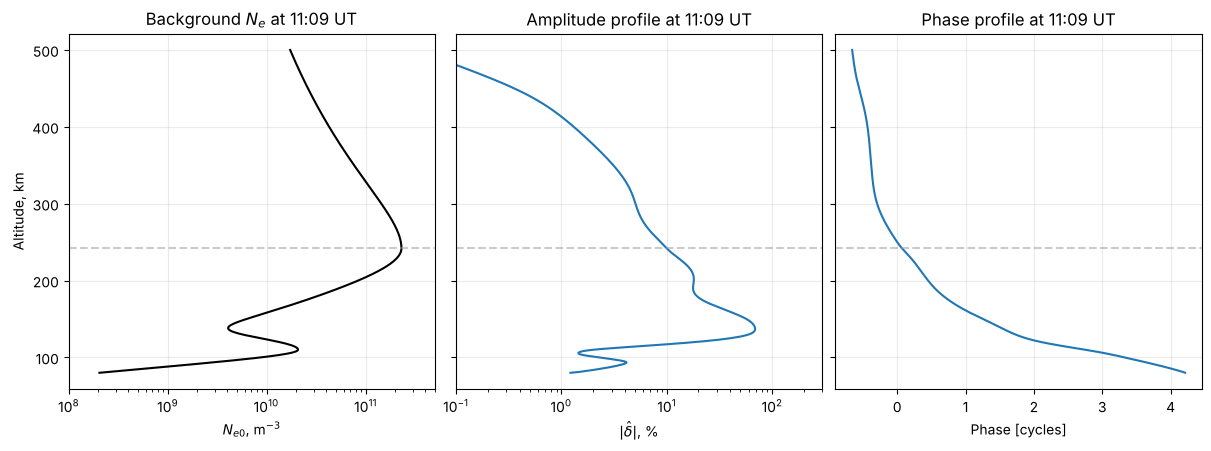

In [6]:
# Vertical structure
fig, axs = plt.subplots(1, 3, figsize = (12, 4.4), sharey=True, constrained_layout=True)
ax = axs[0]
ax.semilogx(N0c[it_max], altF, "k")
ax.axhline(hmF2[it_max], alpha =0.5, color="0.6", ls= "--")
ax.set_xlabel(r"$N_{e0}$, m$^{-3}$")
ax.set_ylabel(r"Altitude, km")
ax.set_xlim(1e8, 5e11)
ax.set_title(rf"Background $N_e$ at {t_lbl}")
ax.grid(alpha=0.25)

#
ax = axs[1]
ax.plot(np.abs(dH_c[it_max]) * 100, altF)
ax.axhline(hmF2[it_max], alpha =0.5, color="0.6", ls= "--")
ax.set_xscale("log"); axs[1].set_xlim(0.1, 300)
ax.set_xlabel(r"$|\hat\delta|$, %"); 
axs[1].set_title(f"Amplitude profile at {t_lbl}"); 
ax.grid(alpha=0.25)

#
ph = np.unwrap(np.angle(dH_c[it_max]))
ph -= np.interp(z_ref, altF, ph)
ax = axs[2]
ax.plot(np.rad2deg(ph) / 360, altF)
ax.axhline(hmF2[it_max], alpha =0.5, color="0.6", ls= "--")
ax.set_xlabel("Phase [cycles]")
ax.set_title(f"Phase profile at {t_lbl}")
ax.grid(alpha=0.25)
plt.show()

## 5. Horizontal structure at 250 km

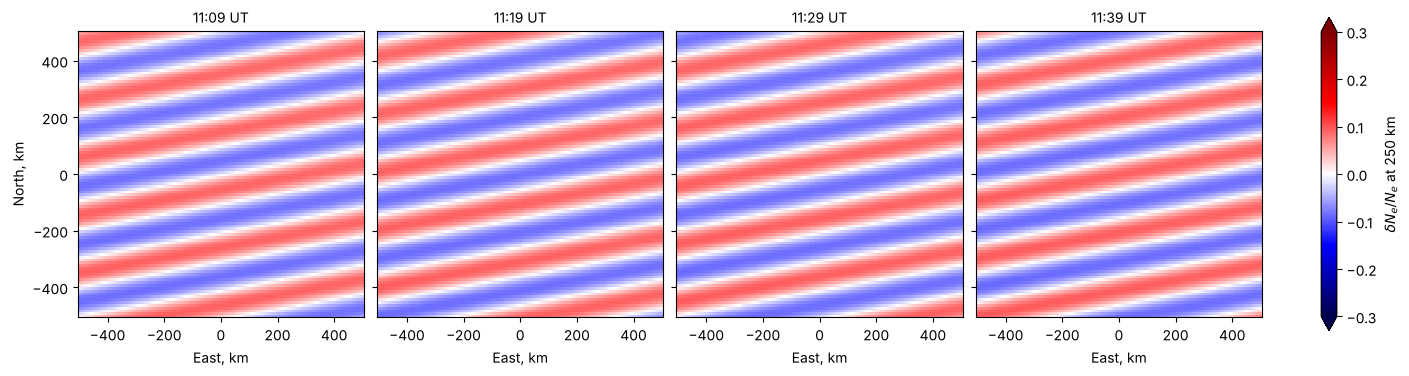

In [7]:
# Horizontal structure at 250 km altitude
z_slice = 250
dt_panels = [0, 10, 20, 30]
ut_s = ut[it_max] + np.array(dt_panels)/60
XX, YY = np.meshgrid(xh, yh)
lat_g, lon_g = latlon_grid(XX.ravel(), YY.ravel())
N0_3d, F2_3d = iri_profiles(ut_s, lat_g, lon_g, altF)
dH3_unit = np.empty(N0_3d.shape, complex)

for i in range(len(ut_s)):
    gw_i = {k: (v[i:i+1] if isinstance(v, np.ndarray) and v.ndim == 2 else v) for k, v in gw_c.items()}
    ms_i = {k: v[i:i+1] for k, v in ms_c.items()}
    dH3_unit[i] = hooke_delta(N0_3d[i:i+1], gw_i, ms_i)[0][0]
icen = np.argmin(XX.ravel() ** 2 + YY.ravel() ** 2)
amp_c = np.array([np.interp(F2_3d["hm"][i, icen], altF, np.abs(dH3_unit[i, icen])) for i in range(len(ut_s))])
dH3 = dH3_unit * (amp_Fpeak / amp_c)[:, None, None]
iz = np.argmin(np.abs(altF - z_slice))
wave_xy = np.exp(1j * (kx * XX.ravel() + ky * YY.ravel()) * 1e3)
N0s = N0_3d[0, :, iz].reshape(XX.shape)
gy, gx = np.gradient(N0s, yh * 1e3, xh * 1e3)
bg_grad = np.nanmedian(np.hypot(gx, gy) / N0s)

norm4 = TwoSlopeNorm(vcenter=0, vmin=-3 * amp_Fpeak, vmax=3 * amp_Fpeak)
fig, axs = plt.subplots(1, len(dt_panels), figsize=(14, 4), sharex=True, sharey=True, constrained_layout=True)
 
for j, (uts, dtp) in enumerate(zip(ut_s, dt_panels)):
    ph = np.exp(-1j * omega * uts * 3600)
    lin = np.real(dH3[j, :, iz] * wave_xy * ph).reshape(XX.shape)
    dmap = np.expm1(lin)                     
    ax = axs[j]
    pc = ax.pcolormesh(xh, yh, dmap, norm=norm4, cmap="seismic", shading="nearest", edgecolors="face", linewidth=0.25)
    ax.set_aspect("equal")
    ax.set_title(f"{(t0 + timedelta(hours=float(uts))):%H:%M} UT", fontsize=10)
    ax.set_xlabel("East, km")
axs[0].set_ylabel("North, km")
 
fig.colorbar(pc, ax=axs, label=rf"$\delta N_e/N_e$ at {z_slice:.0f} km", shrink=0.8, extend="both")
plt.show()